# CSCI 580 — Assignment 6: Perceptron


## Part 1: Heuristic Perceptron Learning

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
data = pd.read_csv("/data-1.csv", header=None)
data.columns = ["x1", "x2", "label"]

# Display the first five rows
print(data.head())


        x1        x2  label
0  0.78051 -0.063669      1
1  0.28774  0.291390      1
2  0.40714  0.178780      1
3  0.29230  0.421700      1
4  0.50922  0.352560      1


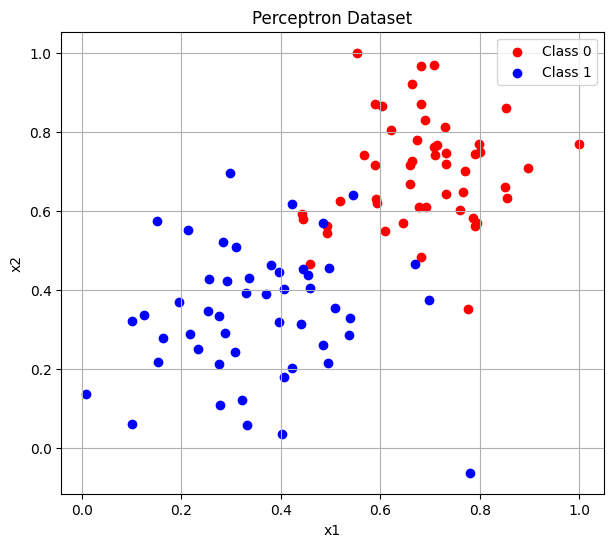

In [3]:

# Separate the two groups
group0 = data[data["label"] == 0]
group1 = data[data["label"] == 1]

# Create scatter plot
plt.figure(figsize=(7, 6))

plt.scatter(group0["x1"], group0["x2"],
            color="red", label="Class 0")

plt.scatter(group1["x1"], group1["x2"],
            color="blue", label="Class 1")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Perceptron Dataset")
plt.legend()
plt.grid(True)
plt.show()


In [4]:

import numpy as np

# Input coordinates
X = data[["x1", "x2"]].values

# Correct class labels
y = data["label"].values

# Set random starting weights and bias
np.random.seed(42)

w = np.random.randn(2)
b = np.random.randn()

# Learning rate
learning_rate = 0.1

print("Starting weights:", w)
print("Starting bias:", b)
print("Learning rate:", learning_rate)


Starting weights: [ 0.49671415 -0.1382643 ]
Starting bias: 0.6476885381006925
Learning rate: 0.1


In [5]:

# Part 1: Heuristic Perceptron Learning

epochs = 65

# Save starting weights and bias
initial_w = w.copy()
initial_b = b

# Record boundary changes
history = [(w.copy(), b)]

for epoch in range(epochs):
    mistakes = 0

    for xi, target in zip(X, y):
        # Calculate weighted sum
        z = np.dot(w, xi) + b

        # Predict class
        prediction = 1 if z >= 0 else 0

        # Update if prediction is wrong
        if prediction != target:
            error = target - prediction

            w = w + learning_rate * error * xi
            b = b + learning_rate * error

            mistakes += 1

    # Save weights and bias after each epoch
    history.append((w.copy(), b))

print("Final weights:", w)
print("Final bias:", b)
print("Total epochs:", epochs)
print("Mistakes in last epoch:", mistakes)


Final weights: [-0.53425085 -0.8637153 ]
Final bias: 0.5476885381006925
Total epochs: 65
Mistakes in last epoch: 4


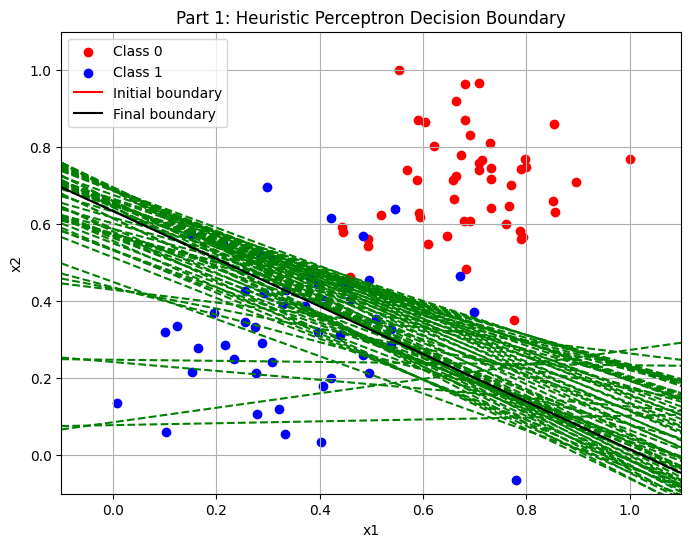

In [6]:

# Step 5: Plot decision boundary evolution

plt.figure(figsize=(8, 6))

# Plot the dataset
plt.scatter(group0["x1"], group0["x2"],
            color="red", label="Class 0")
plt.scatter(group1["x1"], group1["x2"],
            color="blue", label="Class 1")

# X coordinates for decision boundary
x_values = np.linspace(-0.1, 1.1, 100)

# Function to draw a boundary
def plot_boundary(weights, bias, color, style, label):
    if abs(weights[1]) > 1e-10:
        y_values = -(weights[0] * x_values + bias) / weights[1]
        plt.plot(x_values, y_values,
                 color=color, linestyle=style,
                 label=label)
    elif abs(weights[0]) > 1e-10:
        x_boundary = -bias / weights[0]
        plt.axvline(x_boundary, color=color,
                    linestyle=style, label=label)

# Initial boundary (red)
plot_boundary(initial_w, initial_b,
              "red", "-", "Initial boundary")

# Intermediate boundaries (green dashed)
for weights, bias in history[1:-1]:
    plot_boundary(weights, bias,
                  "green", "--", None)

# Final boundary (black)
plot_boundary(w, b, "black", "-", "Final boundary")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Part 1: Heuristic Perceptron Decision Boundary")
plt.xlim(-0.1, 1.1)
plt.ylim(-0.1, 1.1)
plt.legend()
plt.grid(True)
plt.show()


In [7]:

# Step 6: Compare learning rates

rates = [0.01, 0.1, 1.0]
epochs = 65

for rate in rates:
    # Reset weights and bias for fair comparison
    weights = initial_w.copy()
    bias = initial_b

    mistakes_history = []

    for epoch in range(epochs):
        mistakes = 0

        for xi, target in zip(X, y):
            z = np.dot(weights, xi) + bias
            prediction = 1 if z >= 0 else 0

            if prediction != target:
                error = target - prediction
                weights += rate * error * xi
                bias += rate * error
                mistakes += 1

        mistakes_history.append(mistakes)

    # Calculate final accuracy
    predictions = (X @ weights + bias >= 0).astype(int)
    accuracy = np.mean(predictions == y) * 100

    print(f"Learning rate: {rate}")
    print(f"Accuracy: {accuracy:.2f}%")
    print(f"Mistakes in last epoch: {mistakes}")
    print("-------------------------")


Learning rate: 0.01
Accuracy: 93.00%
Mistakes in last epoch: 7
-------------------------
Learning rate: 0.1
Accuracy: 80.00%
Mistakes in last epoch: 4
-------------------------
Learning rate: 1.0
Accuracy: 93.00%
Mistakes in last epoch: 4
-------------------------


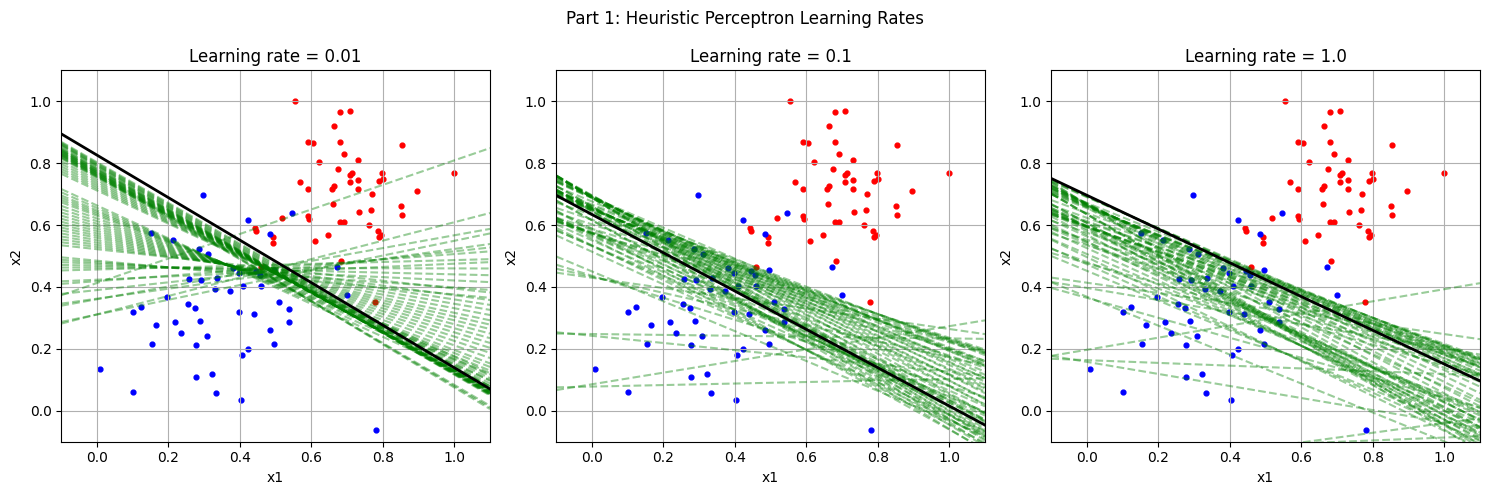

In [8]:

# Compare decision boundaries for 3 learning rates

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, rate in zip(axes, [0.01, 0.1, 1.0]):
    weights = initial_w.copy()
    bias = initial_b
    boundaries = [(weights.copy(), bias)]

    for epoch in range(65):
        for xi, target in zip(X, y):
            prediction = int(np.dot(weights, xi) + bias >= 0)

            if prediction != target:
                error = target - prediction
                weights += rate * error * xi
                bias += rate * error

        boundaries.append((weights.copy(), bias))

    ax.scatter(group0["x1"], group0["x2"],
               color="red", s=12)
    ax.scatter(group1["x1"], group1["x2"],
               color="blue", s=12)

    x_line = np.linspace(-0.1, 1.1, 100)

    for i, (ww, bb) in enumerate(boundaries):
        if abs(ww[1]) > 1e-10:
            y_line = -(ww[0] * x_line + bb) / ww[1]

            if i == 0:
                ax.plot(x_line, y_line, "r-")
            elif i == len(boundaries) - 1:
                ax.plot(x_line, y_line, "k-", linewidth=2)
            else:
                ax.plot(x_line, y_line, "g--", alpha=0.4)

    ax.set_title(f"Learning rate = {rate}")
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.grid(True)

plt.suptitle("Part 1: Heuristic Perceptron Learning Rates")
plt.tight_layout()
plt.show()


## Part 2: Sigmoid Gradient Descent

In [9]:

# Part 2: Sigmoid Gradient Descent

# Sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

# Reset weights and bias
weights_gd = initial_w.copy()
bias_gd = initial_b

learning_rate_gd = 0.1
epochs_gd = 100

# Store boundary changes and errors
history_gd = [(weights_gd.copy(), bias_gd)]
loss_history = []

for epoch in range(epochs_gd):
    for xi, target in zip(X, y):
        # Calculate sigmoid prediction
        z = np.dot(weights_gd, xi) + bias_gd
        prediction = sigmoid(z)

        # Calculate error
        error = target - prediction

        # Update weights and bias
        weights_gd += learning_rate_gd * error * xi
        bias_gd += learning_rate_gd * error

    # Save parameters after each epoch
    history_gd.append((weights_gd.copy(), bias_gd))

    # Calculate log loss
    predictions = sigmoid(X @ weights_gd + bias_gd)
    predictions = np.clip(predictions, 1e-10, 1 - 1e-10)

    loss = -np.mean(
        y * np.log(predictions) +
        (1 - y) * np.log(1 - predictions)
    )

    loss_history.append(loss)

print("Final weights:", weights_gd)
print("Final bias:", bias_gd)
print("Final log loss:", loss_history[-1])


Final weights: [-9.15101001 -9.84377758]
Final bias: 9.527156471909326
Final log loss: 0.16163799363652276


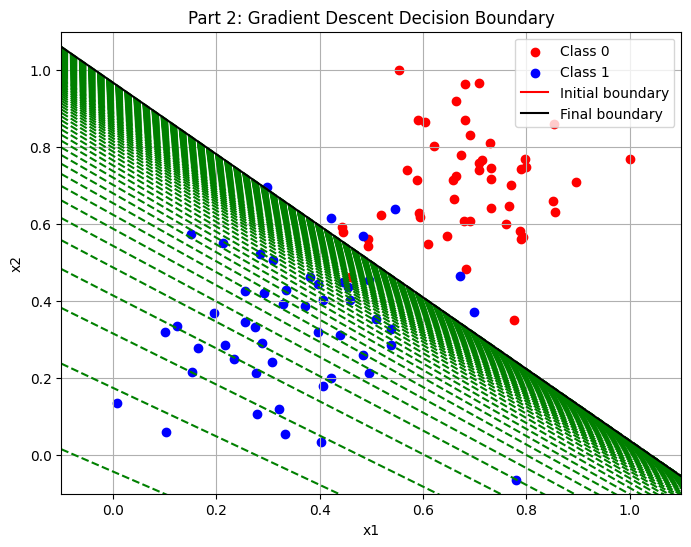

In [10]:

# Step 8: Gradient Descent Decision Boundary

plt.figure(figsize=(8, 6))

# Plot dataset
plt.scatter(group0["x1"], group0["x2"],
            color="red", label="Class 0")
plt.scatter(group1["x1"], group1["x2"],
            color="blue", label="Class 1")

x_values = np.linspace(-0.1, 1.1, 100)

# Draw decision boundary
def draw_gd_boundary(weights, bias, color, style, label=None):
    if abs(weights[1]) > 1e-10:
        y_values = -(weights[0] * x_values + bias) / weights[1]
        plt.plot(x_values, y_values,
                 color=color, linestyle=style,
                 label=label)
    elif abs(weights[0]) > 1e-10:
        plt.axvline(-bias / weights[0],
                    color=color, linestyle=style,
                    label=label)

# Initial boundary (red)
draw_gd_boundary(
    history_gd[0][0], history_gd[0][1],
    "red", "-", "Initial boundary"
)

# Intermediate boundaries (green dashed)
for weights, bias in history_gd[1:-1]:
    draw_gd_boundary(weights, bias, "green", "--")

# Final boundary (black)
draw_gd_boundary(
    history_gd[-1][0], history_gd[-1][1],
    "black", "-", "Final boundary"
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Part 2: Gradient Descent Decision Boundary")
plt.xlim(-0.1, 1.1)
plt.ylim(-0.1, 1.1)
plt.legend()
plt.grid(True)
plt.show()


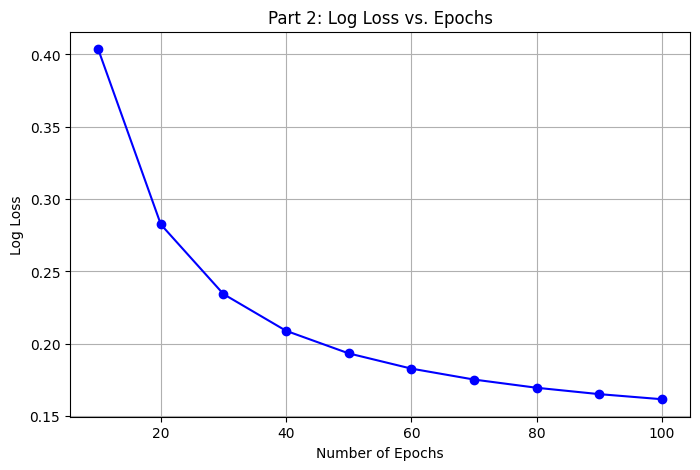

In [11]:

# Step 9: Plot log loss every 10 epochs

# Select epochs 10, 20, 30, ... 100
epoch_numbers = np.arange(10, epochs_gd + 1, 10)

# Get the loss values at those epochs
loss_values = [loss_history[i - 1] for i in epoch_numbers]

# Create the graph
plt.figure(figsize=(8, 5))

plt.plot(epoch_numbers, loss_values,
         marker="o", color="blue")

plt.xlabel("Number of Epochs")
plt.ylabel("Log Loss")
plt.title("Part 2: Log Loss vs. Epochs")
plt.grid(True)

plt.show()


In [12]:

# Step 10: Compare gradient descent settings

rates = [0.01, 0.1, 1.0]
epoch_options = [50, 100]

for rate in rates:
    for max_epochs in epoch_options:

        # Reset to the same starting values
        weights = initial_w.copy()
        bias = initial_b

        for epoch in range(max_epochs):
            for xi, target in zip(X, y):
                prediction = sigmoid(np.dot(weights, xi) + bias)
                error = target - prediction

                weights += rate * error * xi
                bias += rate * error

        # Calculate final predictions
        probabilities = sigmoid(X @ weights + bias)
        classifications = (probabilities >= 0.5).astype(int)

        accuracy = np.mean(classifications == y) * 100

        # Calculate log loss
        probabilities = np.clip(probabilities, 1e-10, 1 - 1e-10)

        loss = -np.mean(
            y * np.log(probabilities) +
            (1 - y) * np.log(1 - probabilities)
        )

        print(f"Rate: {rate}, Epochs: {max_epochs}")
        print(f"Accuracy: {accuracy:.2f}%")
        print(f"Log Loss: {loss:.4f}")
        print("-------------------------")


Rate: 0.01, Epochs: 50
Accuracy: 93.00%
Log Loss: 0.4144
-------------------------
Rate: 0.01, Epochs: 100
Accuracy: 93.00%
Log Loss: 0.3197
-------------------------
Rate: 0.1, Epochs: 50
Accuracy: 93.00%
Log Loss: 0.1933
-------------------------
Rate: 0.1, Epochs: 100
Accuracy: 93.00%
Log Loss: 0.1616
-------------------------
Rate: 1.0, Epochs: 50
Accuracy: 91.00%
Log Loss: 0.2772
-------------------------
Rate: 1.0, Epochs: 100
Accuracy: 93.00%
Log Loss: 0.2556
-------------------------
